# 02. Базовая модель (baseline): TF-IDF + логистическая регрессия

**Что делаем:** учим простую модель определять тип документа (Financial, Legal, Scientific, News, Technical, General)
по фрагменту текста и честно проверяем, насколько хорошо она это делает.

**Зачем нужна базовая модель:** это точка отсчёта. Потом мы обучим более сложную модель (DistilBERT)
и сравним её с базовой на той же тестовой выборке. Если сложная модель окажется не лучше простой,
значит, сложность не оправдана.

**План ноутбука:**
1. Загрузка датасета и первый взгляд на него
2. Разделение на обучающую и тестовую выборки
3. Создание и обучение модели
4. Предсказание на тестовой выборке
5. Метрики качества
6. Матрица ошибок
7. Вывод

## 1. Загрузка датасета

In [1]:
import pandas as pd

### Чтение файла

`pd.read_parquet(путь)` читает файл формата **Parquet** и возвращает таблицу (DataFrame).
Parquet --- формат хранения таблиц, как CSV, но сжатый, быстрый и хранящий типы колонок.
Датасет сохранён в нём ноутбуком `01_data_collection.ipynb`.

**Путь** `"../../data/processed/dataset.parquet"`:
- ноутбук лежит в `ml/notebooks/`, а датасет --- в `data/processed/`;
- `..` означает «подняться на одну папку выше», `../..` --- на две, то есть в корень проекта `FinSight/`;
- в путях используем `/`, а не `\`: в строках Python обратный слэш --- специальный символ.

Результат записываем в переменную `df` (от DataFrame).

In [2]:
df = pd.read_parquet("../../data/processed/dataset.parquet")

### Первый взгляд на данные

Перед обучением всегда смотрим на данные, чтобы убедиться, что загрузилось то, что нужно.

- **`df.shape`** --- размер таблицы в виде пары `(строки, колонки)`. Ожидаем `(12000, 4)`.
  Пишется без скобок в конце, потому что это не функция, а свойство таблицы.

In [3]:
df.shape  # (число строк, число колонок)

(12000, 4)

- **`df.head()`** --- первые 5 строк таблицы. Можно указать другое число: `df.head(10)`.

Колонки датасета:

| Колонка | Что в ней | Нужна для обучения? |
|---|---|---|
| `text` | фрагмент документа, 60--120 слов | да, это вход модели |
| `label` | класс документа | да, это правильный ответ |
| `source` | откуда взят текст | нет, служебная |
| `doc_id` | идентификатор исходного документа | нет, служебная |

In [4]:
df.head()

,text,label,source,doc_id
0,"Net earnings for 2006, 2005 and 2004 were $39....",Financial,edgar_10k,edgar_10k:1334560_2006.htm
1,"A jury in Canton, Ohio, found former police of...",News,cnn_dailymail,cnn_dailymail:2d115e202c7b1ea797daab342d7f5945...
2,We have one reportable operating segment: “Bro...,Financial,edgar_10k,edgar_10k:912752_2017.htm
3,The outer planets are formed slowly by classic...,Scientific,arxiv,arxiv:0704.2860
4,"Our management believes, however, that our sta...",Financial,edgar_10k,edgar_10k:1626078_2016.htm


- **`df["label"]`** --- выбрать одну колонку по имени.
- **`.value_counts()`** --- посчитать, сколько раз встречается каждое значение.

Проверяем **баланс классов**: если одного класса много, а другого мало, модель будет чаще выбирать большой класс.
У нас ровно по 2000 текстов на класс.

In [5]:
df["label"].value_counts()  # по 2000 на каждый из 6 классов

label
Financial     2000
News          2000
Scientific    2000
Legal         2000
General       2000
Technical     2000
Name: count, dtype: int64

## 2. Разделение на обучающую и тестовую выборки

Модель учится на **train**, а качество проверяется на **test** --- текстах, которых она не видела.
Если проверять на тех же данных, оценка будет завышена: модель могла просто их запомнить (переобучение).

Функция `train_test_split` случайно делит данные и возвращает четыре объекта:

| Объект | Что это | Размер |
|---|---|---|
| `X_train` | тексты для обучения | 9600 |
| `X_test` | тексты для проверки | 2400 |
| `y_train` | правильные классы для `X_train` | 9600 |
| `y_test` | правильные классы для `X_test` | 2400 |

Аргументы:

| Аргумент | Значение | Зачем |
|---|---|---|
| `df["text"]` | признаки (X) | то, что подаётся на вход модели |
| `df["label"]` | ответы (y) | то, что модель учится предсказывать |
| `test_size` | `0.2` | 20% данных уходит в test, остальные 80% в train |
| `random_state` | `42` | фиксирует случайность: при каждом запуске одно и то же разбиение. Нужно, чтобы результаты повторялись и разные модели сравнивались на одном тесте. Само число не важно |
| `stratify` | `df["label"]` | сохраняет доли классов: в train и test каждого класса ровно по 1/6 |

**Правило:** test используем только для финальной оценки. Всё, что учится на данных, учится только на train.

`from sklearn.model_selection import train_test_split` --- импорт одной функции из библиотеки **scikit-learn**
(сокращённо `sklearn`). Это главная библиотека классического машинного обучения в Python:
в ней есть модели, метрики и инструменты подготовки данных.

In [6]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    df["text"],  # X: тексты, вход модели
    df["label"],  # y: классы, правильные ответы
    test_size=0.2,  # 20% в test, 80% в train
    random_state=42,  # одно и то же разбиение при каждом запуске
    stratify=df["label"],  # одинаковые доли классов в train и test
)

### Проверка разделения

- `X_train.shape` и `X_test.shape` --- размеры частей. У одной колонки размер записывается как `(9600,)`:
  запятая означает, что это одномерный набор из 9600 элементов.
- `print(...)` выводит значения на экран. Он нужен, потому что ноутбук сам показывает только результат
  **последней** строки ячейки.
- `y_test.value_counts()` --- сколько текстов каждого класса попало в тест. Благодаря `stratify` --- ровно по 400.

In [7]:
print(X_train.shape, X_test.shape)  # ожидаем (9600,) (2400,)
y_test.value_counts()  # по 400 текстов каждого класса

(9600,) (2400,)


label
General       400
Financial     400
News          400
Scientific    400
Technical     400
Legal         400
Name: count, dtype: int64

## 3. Модель

`Pipeline` склеивает несколько шагов в один объект, который работает как обычная модель.
Он создаётся из списка пар `("имя шага", объект)`. Имена придумываем сами.
Все шаги, кроме последнего, должны уметь преобразовывать данные (`transform`), а последний обычно является моделью.

```
Текст -> TfidfVectorizer -> числа -> LogisticRegression -> класс
```

**`TfidfVectorizer`** превращает текст в числа, так как модель не умеет работать с текстом напрямую.
Для каждого слова считается вес: он выше, если слово часто встречается в этом тексте, но редко в остальных.
Словарь и веса запоминаются только по train. Все параметры сейчас стандартные.

**`LogisticRegression`** --- простой и быстрый линейный классификатор. Он считает вероятность каждого класса и выбирает самый вероятный.
Аргумент `max_iter=1000` --- максимальное число итераций обучения. Значение по умолчанию (100) может оказаться слишком маленьким для текстов.

Что происходит при вызовах:

| Вызов | Шаг TF-IDF | Шаг модели |
|---|---|---|
| `pipe.fit(X_train, y_train)` | учит словарь и преобразует train (`fit_transform`) | обучается на полученных числах (`fit`) |
| `pipe.predict(X_test)` | только преобразует (`transform`), ничему не учится | только предсказывает (`predict`) |

Благодаря этому информация из test не попадает в обучение (нет утечки данных).
Это **базовая модель (baseline)**: точка отсчёта, с которой потом сравним DistilBERT.

### Как TF-IDF превращает текст в числа

Модель умеет работать только с числами, поэтому каждый текст нужно превратить в **вектор** --- список чисел.
TF-IDF делает это так: одно число на каждое слово словаря. Число показывает, насколько слово **важно для этого текста**.

**Формула** (именно так считает `TfidfVectorizer` с настройками по умолчанию):

$$\text{tfidf}(t, d) = \text{tf}(t, d) \cdot \text{idf}(t)$$

- $t$ --- слово (term), $d$ --- текст (document);
- $\text{tf}(t, d)$ --- **сколько раз слово встречается в тексте**;
- $\text{idf}(t)$ --- **насколько слово редкое во всей коллекции текстов**:

$$\text{idf}(t) = \ln\frac{1 + n}{1 + \text{df}(t)} + 1$$

- $n$ --- число текстов в коллекции, $\text{df}(t)$ --- в скольких текстах встречается слово.

Слово, которое есть везде (например, `the`), получает минимальный idf, равный 1. Редкое слово получает больший idf.
Единицы в формуле добавлены, чтобы не делить на ноль и чтобы вес частых слов не обнулялся.

В конце вектор каждого текста **нормируется**: все числа делятся на длину вектора
$\sqrt{x_1^2 + x_2^2 + \ldots}$. После этого длинные и короткие тексты сравнимы: важны пропорции, а не длина.

**Пример на трёх текстах** ($n = 3$):

| Текст | Содержание |
|---|---|
| 1 | the company shall pay |
| 2 | the company reported revenue |
| 3 | the court said |

Шаг 1 --- idf каждого слова:

| Слово | В скольких текстах ($\text{df}$) | $\text{idf}$ |
|---|---|---|
| the | 3 | $\ln\frac{4}{4} + 1 = 1{,}000$ |
| company | 2 | $\ln\frac{4}{3} + 1 = 1{,}288$ |
| shall, pay, reported, revenue, court, said | 1 | $\ln\frac{4}{2} + 1 = 1{,}693$ |

Шаг 2 --- вектор первого текста до нормировки (каждое слово встречается один раз, $\text{tf} = 1$):
`the` = 1,000; `company` = 1,288; `shall` = 1,693; `pay` = 1,693; остальные слова = 0.

Шаг 3 --- нормировка. Длина вектора $\sqrt{1{,}000^2 + 1{,}288^2 + 1{,}693^2 + 1{,}693^2} = 2{,}897$.
Делим каждое число на 2,897:

| | company | court | pay | reported | revenue | said | shall | the |
|---|---|---|---|---|---|---|---|---|
| **текст 1** | 0,445 | 0 | 0,584 | 0 | 0 | 0 | 0,584 | 0,345 |

Видно главное: у слова `the` самый маленький вес, хотя оно есть в тексте, --- оно встречается везде и не помогает
отличить один текст от другого. Самые большие веса у `shall` и `pay`, которых больше нет нигде.

Ячейка ниже считает то же самое кодом, чтобы можно было сверить. В нашем настоящем датасете словарь --- десятки тысяч слов,
поэтому вектор каждого текста очень длинный и почти весь состоит из нулей.

In [8]:
from sklearn.feature_extraction.text import TfidfVectorizer

# Игрушечный пример: те же три текста, что в таблице выше
toy_texts = [
    "the company shall pay",
    "the company reported revenue",
    "the court said",
]

toy_vectorizer = TfidfVectorizer()
toy_vectors = toy_vectorizer.fit_transform(
    toy_texts
)  # учим словарь и сразу переводим в числа

# Превращаем результат в таблицу: строки - тексты, колонки - слова словаря
pd.DataFrame(
    toy_vectors.toarray(),  # toarray() показывает все числа, включая нули
    columns=toy_vectorizer.get_feature_names_out(),  # слова словаря
).round(3)

,company,court,pay,reported,revenue,said,shall,the
0,0.445,0.000,0.584,0.000,0.000,0.000,0.584,0.345
1,0.445,0.000,0.000,0.584,0.584,0.000,0.000,0.345
2,0.000,0.652,0.000,0.000,0.000,0.652,0.000,0.385


### Создание модели

Импорты:
- `TfidfVectorizer` --- из модуля `sklearn.feature_extraction.text` (извлечение признаков из текста);
- `LogisticRegression` --- из `sklearn.linear_model` (линейные модели);
- `Pipeline` --- из `sklearn.pipeline`.

Создание `Pipeline(...)` ещё ничего не обучает: это только описание того, из каких шагов состоит модель.

In [9]:
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.linear_model import LogisticRegression
from sklearn.pipeline import Pipeline

pipe = Pipeline(
    steps=[
        ("tfidfvectorizer", TfidfVectorizer()),  # шаг 1: текст -> числа (веса слов)
        ("log_regres", LogisticRegression(max_iter=1000)),  # шаг 2: числа -> класс
    ]
)

### Обучение

`pipe.fit(X_train, y_train)` --- обучение модели. Передаём **тексты** и **правильные ответы** обучающей выборки.

Что происходит внутри:
1. TF-IDF составляет словарь по текстам train и превращает их в числа;
2. логистическая регрессия подбирает веса слов так, чтобы ответы на train были как можно точнее.

Ноутбук выводит схему Pipeline --- это значит, что обучение прошло без ошибок. Занимает несколько секунд.

In [10]:
pipe.fit(X_train, y_train)  # обучение: тексты + правильные ответы

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators <combining_estimators>` for more details.","[('tfidfvectorizer', ...), ('log_regres', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing <metadata_routing>`.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
Name,Type,Value
"classes_ classes_: ndarray of shape (n_classes,)The classes labels. Only exist if the last step of the pipeline is aclassifier.","ndarray[object](6,)","['Financial','General','Legal','News','Scientific','Technical']"
,"input input: {'filename', 'file', 'content'}, default='content'- If `'filename'`, the sequence passed as an argument to fit is expected to be a list of filenames that need reading to fetch the raw content to analyze.- If `'file'`, the sequence items must have a 'read' method (file-like object) that is called to fetch the bytes in memory.- If `'content'`, the input is expected to be a sequence of items that can be of type string or byte.",'content'
,"encoding encoding: str, default='utf-8'If bytes or files are given to analyze, this encoding is used todecode.",'utf-8'
,"decode_error decode_error: {'strict', 'ignore', 'replace'}, default='strict'Instruction on what to do if a byte sequence is given to analyze thatcontains characters not of the given `encoding`. By default, it is'strict', meaning that a UnicodeDecodeError will be raised. Othervalues are 'ignore' and 'replace'.",'strict'
,"strip_accents strip_accents: {'ascii', 'unicode'} or callable, default=NoneRemove accents and perform other character normalizationduring the preprocessing step.'ascii' is a fast method that only works on characters that havea direct ASCII mapping.'unicode' is a slightly slower method that works on any characters.None (default) means no character normalization is performed.Both 'ascii' and 'unicode' use NFKD normalization from:func:`unicodedata.normalize`.",None
,"lowercase lowercase: bool, default=TrueConvert all characters to lowercase before tokenizing.",True


### Как логистическая регрессия выбирает класс

Мы уже знаем, что каждый текст --- это вектор $x$ из весов TF-IDF. Для **каждого класса** $c$ модель хранит
свой набор весов $w_c$ (по одному весу на каждое слово словаря) и одно число $b_c$ (сдвиг, bias).

**Шаг 1 --- оценка (score) для каждого класса:**

$$z_c = w_c \cdot x + b_c = w_{c,1} x_1 + w_{c,2} x_2 + \ldots + b_c$$

Каждое слово текста «голосует» за класс: его TF-IDF умножается на вес этого слова в классе.
Если у слова `shall` большой положительный вес в классе Legal, то текст со словом `shall` набирает много очков у Legal.

**Шаг 2 --- превращение оценок в вероятности (функция softmax):**

$$P(c \mid x) = \frac{e^{z_c}}{\sum_k e^{z_k}}$$

Экспонента $e^{z}$ делает все числа положительными, а деление на сумму --- так, чтобы вероятности
всех классов в сумме давали 1.

**Шаг 3 --- ответ:** класс с наибольшей вероятностью.

**Пример на пальцах.** Пусть для текста получились оценки: Legal = 3, Financial = 1, News = 0.
Тогда $e^3 = 20{,}1$, $e^1 = 2{,}7$, $e^0 = 1$, сумма = 23,8.
Вероятности: Legal = 20,1 / 23,8 = **0,84**, Financial = 0,11, News = 0,04. Ответ --- Legal.

**Что происходит при обучении (`fit`).** Модель начинает со случайных весов и много раз их подправляет так,
чтобы для текстов train вероятность правильного класса была как можно выше.
`max_iter=1000` --- максимальное число таких подправлений.

Ячейка ниже заглядывает внутрь нашей обученной модели:
1. самые важные слова каждого класса --- слова с наибольшими весами;
2. разбор одного текста из теста: какие слова дали больше всего очков, какие получились оценки $z$
   и вероятности --- и совпадают ли они с тем, что выдаёт `predict_proba`.

### Пример: 6 классов --- 6 наборов весов --- 6 сумм

У модели **свой набор весов для каждого класса**. Для одного текста она считает **по сумме на каждый класс**,
превращает суммы в вероятности и выбирает самую большую. Разберём на маленьком примере:
в словаре всего 3 слова, классов для простоты три.

**Веса модели** (выучены при обучении):

| | shall | revenue | said |
|---|---|---|---|
| **Legal** | +3,0 | 0,0 | −0,5 |
| **Financial** | −0,5 | +2,5 | 0,0 |
| **News** | −1,0 | +0,3 | +2,0 |

Читаем по строкам: у Legal слово `shall` даёт много очков, а у News то же слово очки **отнимает**.
Веса бывают отрицательными: такое слово говорит «это скорее **не** этот класс».

**Текст** «The company shall pay» после TF-IDF: `shall` = 0,6, `revenue` = 0, `said` = 0.

**Шаг 1 --- сумма для каждого класса.** Умножаем TF-IDF каждого слова на его вес в этом классе и складываем:

| Класс | Расчёт | Сумма $z$ |
|---|---|---|
| Legal | 0,6 · 3,0 + 0 · 0,0 + 0 · (−0,5) | **1,8** |
| Financial | 0,6 · (−0,5) + 0 + 0 | −0,3 |
| News | 0,6 · (−1,0) + 0 + 0 | −0,6 |

Слова, которых нет в тексте, ничего не добавляют: их TF-IDF равен 0.

**Шаг 2 --- вероятности (softmax).** $e^{1{,}8} = 6{,}05$, $e^{-0{,}3} = 0{,}74$, $e^{-0{,}6} = 0{,}55$, сумма = 7,34.
Legal = 6,05 / 7,34 = **0,82**, Financial = 0,74 / 7,34 = 0,10, News = 0,55 / 7,34 = 0,07.

**Шаг 3 --- ответ:** Legal.

**В нашей модели всё то же самое, только больше:**
- 6 строк весов (классы) × 42 187 колонок (слова) --- это `model.coef_`, его размер выводит ячейка ниже;
- плюс 6 сдвигов $b$, по одному на класс (`model.intercept_`), --- «стартовые очки» класса до подсчёта слов;
- для каждого текста считается 6 сумм --- их видно ниже в колонке «оценка z».

**Важно:** шесть наборов весов учатся **не по отдельности, а вместе**. При обучении модель смотрит на вероятность
правильного класса после softmax, а она зависит сразу от всех шести сумм. Поэтому веса подстраиваются друг под друга:
например, `shall` получает большой вес у Legal и одновременно отрицательный у News --- так модель надёжнее
отделяет договоры от новостей.

In [11]:
import numpy as np

vectorizer = pipe.named_steps["tfidfvectorizer"]  # обученный шаг 1
model = pipe.named_steps["log_regres"]  # обученный шаг 2
words = vectorizer.get_feature_names_out()  # словарь: слово по номеру

print("Размер словаря:", len(words))
print("Размер матрицы весов:", model.coef_.shape)  # (6 классов, число слов)
print()

# 1. Самые важные слова каждого класса: 8 слов с наибольшим весом
for class_name, class_weights in zip(model.classes_, model.coef_):
    top = np.argsort(class_weights)[-8:][::-1]  # номера 8 самых больших весов
    print(f"{class_name:<11}", ", ".join(words[top]))
print()

# 2. Разбор одного текста из теста
text = X_test.iloc[0]
x = vectorizer.transform([text]).toarray()[0]  # вектор TF-IDF этого текста
print("Текст:", text[:200], "...")
print("Правильный класс:", y_test.iloc[0])
print("Ненулевых чисел в векторе:", np.count_nonzero(x), "из", len(x))
print()

z = model.coef_ @ x + model.intercept_  # шаг 1: оценка для каждого класса
probs = np.exp(z) / np.exp(z).sum()  # шаг 2: softmax

predicted = model.classes_[probs.argmax()]
contributions = model.coef_[probs.argmax()] * x  # вклад каждого слова в выбранный класс
top_words = np.argsort(contributions)[-5:][::-1]
print(
    f"Слова, давшие больше всего очков классу {predicted}:", ", ".join(words[top_words])
)
print()

pd.DataFrame(
    {
        "оценка z": z.round(2),
        "вероятность (вручную)": probs.round(3),
        "вероятность (predict_proba)": pipe.predict_proba([text])[0].round(3),
    },
    index=model.classes_,
)

Размер словаря: 42187
Размер матрицы весов: (6, 42187)

Financial   our, company, we, products, and, market, business, financial
General     was, his, century, history, early, he, as, often
Legal       or, shall, any, agreement, such, and, all, company
News        said, he, who, she, his, says, they, president
Scientific  we, of, the, model, show, energy, field, quantum
Technical   you, it, file, windows, use, my, your, server

Текст: Andersonville may refer to: Places United States Andersonville, Georgia, site of an American Civil War prisoner of war camp Andersonville Prison, Confederate prisoner of war camp in Georgia holding Un ...
Правильный класс: General
Ненулевых чисел в векторе: 44 из 42187

Слова, давшие больше всего очков классу General: war, refer, an, american, district



,оценка z,вероятность (вручную),вероятность (predict_proba)
Financial,0.09,0.059,0.059
General,2.61,0.740,0.740
Legal,-1.91,0.008,0.008
News,1.01,0.149,0.149
Scientific,-0.92,0.022,0.022
Technical,-0.88,0.023,0.023


## 4. Предсказание на тестовой выборке

`pipe.predict(X_test)` получает только тексты, а правильные ответы не видит.
Pipeline сам переводит тексты в числа по словарю, выученному на train, и выдаёт класс для каждого текста.

- `y_pred` --- ответы модели;
- `y_test` --- правильные ответы. Дальше мы сравниваем `y_pred` с `y_test`.

In [12]:
y_pred = pipe.predict(X_test)  # ответы модели для 2400 текстов теста

## 5. Метрики качества

`classification_report` сравнивает правильные ответы с ответами модели и считает метрики для каждого класса.

| Метрика | Вопрос, на который отвечает | Пример из нашего результата |
|---|---|---|
| **precision** (точность) | Когда модель назвала класс, как часто она права? | General: 0,847 --- из текстов, которые модель назвала General, верно определено 84,7% |
| **recall** (полнота) | Какую долю текстов этого класса модель нашла? | News: 0,845 --- из 400 новостей модель распознала 84,5%, остальные отнесла к другим классам |
| **f1-score** | Общая оценка: среднее гармоническое precision и recall | General: 0,874 --- самый низкий результат среди классов |
| **support** | Сколько текстов этого класса в тесте | 400 у каждого |

Итоговые строки:
- **accuracy** --- доля всех верных ответов;
- **macro avg** --- простое среднее по классам, все классы имеют одинаковый вес;
- **weighted avg** --- среднее с учётом числа текстов в классе. У нас классы одинакового размера, поэтому оно совпадает с macro avg.

Аргумент `digits=3` просто выводит три знака после запятой.

**Как связаны precision и recall.** Модель, которая называет News только самые очевидные новости,
будет редко ошибаться (высокий precision), но пропустит много новостей (низкий recall). И наоборот.
F1 высокий, только если высоки обе метрики.

`from sklearn.metrics import classification_report` --- импорт функции из модуля метрик.
`classification_report(y_test, y_pred, digits=3)` --- сначала правильные ответы, потом ответы модели.
Функция возвращает текст-таблицу, поэтому оборачиваем её в `print`, иначе переносы строк отобразятся как `\n`.

**А sensitivity и specificity?** Sensitivity (чувствительность) --- это то же самое, что recall, она уже есть в таблице.
Specificity (специфичность) --- доля текстов **не** этого класса, которые модель правильно **не** отнесла к нему.
Эти метрики придуманы для задач с двумя классами (например, «болен --- здоров» в медицине).
При шести классах их считают «каждый класс против остальных», и specificity получается почти всегда очень высокой:
текстов чужих классов в пять раз больше, чем своего. Поэтому для многоклассовой классификации
обычно используют precision, recall и F1.

In [13]:
from sklearn.metrics import classification_report

# Сравниваем правильные ответы (y_test) с ответами модели (y_pred)
print(classification_report(y_test, y_pred, digits=3))

              precision    recall  f1-score   support

   Financial      0.955     0.963     0.959       400
     General      0.847     0.902     0.874       400
       Legal      0.985     0.985     0.985       400
        News      0.942     0.845     0.891       400
  Scientific      0.968     0.983     0.975       400
   Technical      0.961     0.975     0.968       400

    accuracy                          0.942      2400
   macro avg      0.943     0.942     0.942      2400
weighted avg      0.943     0.942     0.942      2400



## 6. Матрица ошибок

Показывает, **что именно с чем модель путает**:
- **строка** --- какой класс был на самом деле;
- **столбец** --- что ответила модель;
- **диагональ** --- верные ответы, всё остальное --- ошибки.

Аргументы `sns.heatmap`:

| Аргумент | Что делает |
|---|---|
| `cn` | таблица чисел, которую рисуем |
| `annot=True` | пишет числа внутри клеток |
| `fmt="d"` | показывает числа как целые |
| `xticklabels`, `yticklabels` | подписывают столбцы и строки названиями классов |

`seaborn` рисует саму карту, а `matplotlib` (`plt`) отвечает за подписи осей и показ картинки.

`pipe.classes_` --- список классов, которые модель узнала при обучении, в алфавитном порядке.
Передаём его в `labels=`, чтобы задать порядок строк и столбцов, и в подписи, чтобы они совпадали с числами.

**Как читать результат:** ищем самые большие числа **вне** диагонали --- это классы, которые модель путает чаще всего.

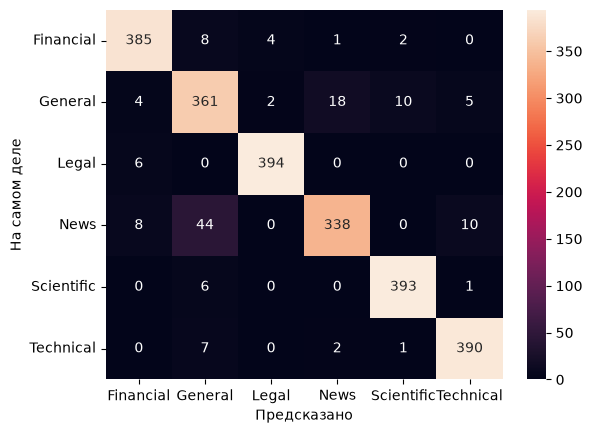

In [ ]:
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.metrics import confusion_matrix

# Таблица чисел: строки --- правильные классы, столбцы --- ответы модели

# первый аргумент (y_test, правильные ответы) задаёт строки;
# второй аргумент (y_pred, ответы модели) задаёт столбцы.

cn = confusion_matrix(y_test, y_pred, labels=pipe.classes_)

sns.heatmap(
    cn,
    annot=True,  # писать числа внутри клеток
    fmt="d",  # показывать целые числа
    xticklabels=pipe.classes_,  # подписи столбцов
    yticklabels=pipe.classes_,  # подписи строк
)

plt.xlabel("Предсказано")
plt.ylabel("На самом деле")
plt.show()

## 7. Вывод

Accuracy и macro-F1 на тестовой выборке равны **0,942**, это выше целевых значений из записки (0,85 и 0,82).

Чаще всего модель путает **News и General** (44 новости приняты за General). Это ожидаемо:
статья о культуре или истории по стилю похожа и на новость, и на энциклопедический текст.

**История версий датасета.** На первой версии accuracy была 0,959, но модель опиралась на подсказки:
у Financial среди самых важных слов были `2020`, `2019` и `covid` (все отчёты были за 2020 год),
у News --- слово `cnn`. После того как отчёты взяты за 2006--2020 годы, а упоминания CNN удалены,
точность снизилась до 0,942. Зато теперь модель опирается на жанр текста (`shall`, `agreement` у Legal,
`said`, `told` у News), и оценка честнее. Подробности --- в `docs/data.md`.

Этот результат --- точка отсчёта: с ним сравним дообученную модель DistilBERT на той же тестовой выборке.